In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
from astropy.io import fits
from matplotlib import pyplot as plt

ROOT = Path.cwd()
FITS_DIR = ROOT / "fits_ready"
FIGS_DIR = ROOT / "Imgs"
FIGS_DIR.mkdir(exist_ok=True)


In [5]:
# -------------------------------------------------------
# MUSE 30 Doradus Halpha datasets
# -------------------------------------------------------

BINS = tuple(range(6))

DATASET_PREFIX = "SAMFP-30Dor-H"
SUFFIX = "-ivsv"

datasets = [
    {
        "instrument": "SAMFP",
        "bin": bin_level,
        "line": "Halpha",
        "filename": f"{DATASET_PREFIX}-bin{bin_level}{SUFFIX}.fits",
        "label": rf"${2**bin_level}\times{2**bin_level}$",
    }
    for bin_level in BINS
]

pd.DataFrame(datasets)


,instrument,bin,line,filename,label
0,SAMFP,0,Halpha,SAMFP-30Dor-H-bin0-ivsv.fits,$1\times1$
1,SAMFP,1,Halpha,SAMFP-30Dor-H-bin1-ivsv.fits,$2\times2$
2,SAMFP,2,Halpha,SAMFP-30Dor-H-bin2-ivsv.fits,$4\times4$
3,SAMFP,3,Halpha,SAMFP-30Dor-H-bin3-ivsv.fits,$8\times8$
4,SAMFP,4,Halpha,SAMFP-30Dor-H-bin4-ivsv.fits,$16\times16$
5,SAMFP,5,Halpha,SAMFP-30Dor-H-bin5-ivsv.fits,$32\times32$


In [6]:
def load_velocity_dataset(entry):
    fits_path = FITS_DIR / entry["filename"]

    if not fits_path.exists():
        raise FileNotFoundError(f"Missing FITS file: {fits_path}")

    with fits.open(fits_path) as hdul:
        sb = hdul["MOM0"].data.astype(float)
        vv = hdul["MOM1"].data.astype(float)

    yy, xx = np.indices(vv.shape)

    df = pd.DataFrame({
        "X": xx.ravel(),
        "Y": yy.ravel(),
        "VV": vv.ravel(),
        "SB": sb.ravel(),
    })

    df = df.dropna(subset=["VV", "SB"])

    df["instrument"] = entry["instrument"]
    df["line"] = entry["line"]
    df["label"] = entry["label"]
    df["filename"] = entry["filename"]
    df["bin"] = entry["bin"]

    mean_v = df["VV"].mean()
    df["RV_centered"] = df["VV"] - mean_v

    raw = {
        "sb": sb,
        "vv": vv,
        "instrument": entry["instrument"],
        "line": entry["line"],
        "label": entry["label"],
        "filename": entry["filename"],
        "bin": entry["bin"],
    }

    return df, raw


In [7]:
processed_list = []
raw_data = {}

for entry in datasets:
    df, raw = load_velocity_dataset(entry)
    processed_list.append(df)

    key = (entry["line"], entry["instrument"], entry["bin"])
    raw_data[key] = raw

processed_data = pd.concat(processed_list, ignore_index=True)

print(f"Loaded {len(datasets)} MUSE 30 Doradus Halpha datasets")


Loaded 6 MUSE 30 Doradus Halpha datasets


In [8]:
processed_data.head()

,X,Y,VV,SB,instrument,line,label,filename,bin,RV_centered
0,13,0,253.611630,0.008255,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-22.044714
1,24,0,250.208933,0.034307,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-25.447411
2,27,0,301.713477,0.028794,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,26.057133
3,30,0,224.319115,0.019941,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-51.337229
4,36,0,228.470355,0.016673,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-47.185989


In [9]:
processed_data.groupby("bin")[["VV", "RV_centered", "SB"]].describe()


VV                                                             \
        count        mean        std         min         25%         50%   
bin                                                                        
0    476204.0  275.656344  18.010219  185.778288  262.476633  274.422101   
1    119575.0  275.707027  18.544795 -459.070627  262.545249  274.530517   
2     29920.0  275.729860  18.240265   55.980389  262.580078  274.580701   
3      7482.0  275.734873  18.014237  108.474467  262.731217  274.581301   
4      1849.0  276.050566  17.619155  224.483995  263.403454  274.925907   
5       441.0  276.925239  17.170523  244.444150  264.249274  276.117808   

                            RV_centered                ...             \
            75%         max       count          mean  ...        75%   
bin                                                    ...              
0    287.019325  359.985411    476204.0  7.227003e-14  ...  11.362981   
1    287.136610  576.391258    119575.0  4.186376e-14  ...  11.429584   
2    287.128630  490.319095     29920.0  1.167266e-14  ...  11.398769   
3    287.032909  333.910162      7482.0 -2.406842e-14  ...  11.298037   
4    287.012701  331.885899      1849.0 -7.870154e-15  ...  10.962136   
5    287.531172  328.320237       441.0 -4.073134e-14  ...  10.605933   

                       SB                                                    \
            max     count      mean       std       min       25%       50%   
bin                                                                           
0     84.329067  476204.0  0.084707  0.090150  0.003212  0.024530  0.055391   
1    300.684231  119575.0  0.085294  0.091173  0.001099  0.024313  0.055523   
2    214.589234   29920.0  0.090065  0.096126  0.001696  0.025695  0.058593   
3     58.175289    7482.0  0.095403  0.101196  0.004614  0.027334  0.062516   
4     55.835334    1849.0  0.133501  0.139684  0.007056  0.038520  0.086439   
5     51.394999     441.0  0.147956  0.150612  0.008496  0.043039  0.098801   

                    
          75%  max  
bin                 
0    0.110285  1.0  
1    0.110990  1.0  
2    0.117360  1.0  
3    0.124841  1.0  
4    0.174174  1.0  
5    0.192965  1.0  

[6 rows x 24 columns]

In [10]:
processed_data

,X,Y,VV,SB,instrument,line,label,filename,bin,RV_centered
0,13,0,253.611630,0.008255,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-22.044714
1,24,0,250.208933,0.034307,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-25.447411
2,27,0,301.713477,0.028794,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,26.057133
3,30,0,224.319115,0.019941,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-51.337229
4,36,0,228.470355,0.016673,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-47.185989
...,...,...,...,...,...,...,...,...,...,...
635466,16,20,267.219200,0.165489,SAMFP,Halpha,$32\times32$,SAMFP-30Dor-H-bin5-ivsv.fits,5,-9.706039
635467,17,20,266.592668,0.096104,SAMFP,Halpha,$32\times32$,SAMFP-30Dor-H-bin5-ivsv.fits,5,-10.332570
635468,18,20,275.313613,0.040436,SAMFP,Halpha,$32\times32$,SAMFP-30Dor-H-bin5-ivsv.fits,5,-1.611626
635469,19,20,279.422177,0.051220,SAMFP,Halpha,$32\times32$,SAMFP-30Dor-H-bin5-ivsv.fits,5,2.496938


In [11]:
# Convenient dictionary: one DataFrame per bin level
ha_muse = {
    bin_level: processed_data[
        processed_data["bin"] == bin_level
    ].copy()
    for bin_level in BINS
}

# Optional aliases, kept for compatibility with the original notebook
ha_muse_bin0 = ha_muse[0]
ha_muse_bin1 = ha_muse[1]
ha_muse_bin2 = ha_muse[2]
ha_muse_bin3 = ha_muse[3]
ha_muse_bin4 = ha_muse[4]
ha_muse_bin5 = ha_muse[5]


In [12]:
instrument_colors = {
    "MUSE": "black",
}

line_order = ["Halpha"]


## Surface brightness vs radial velocity

The following panels compare the complete H\(\alpha\) intensity–velocity distribution across spatial binning levels.


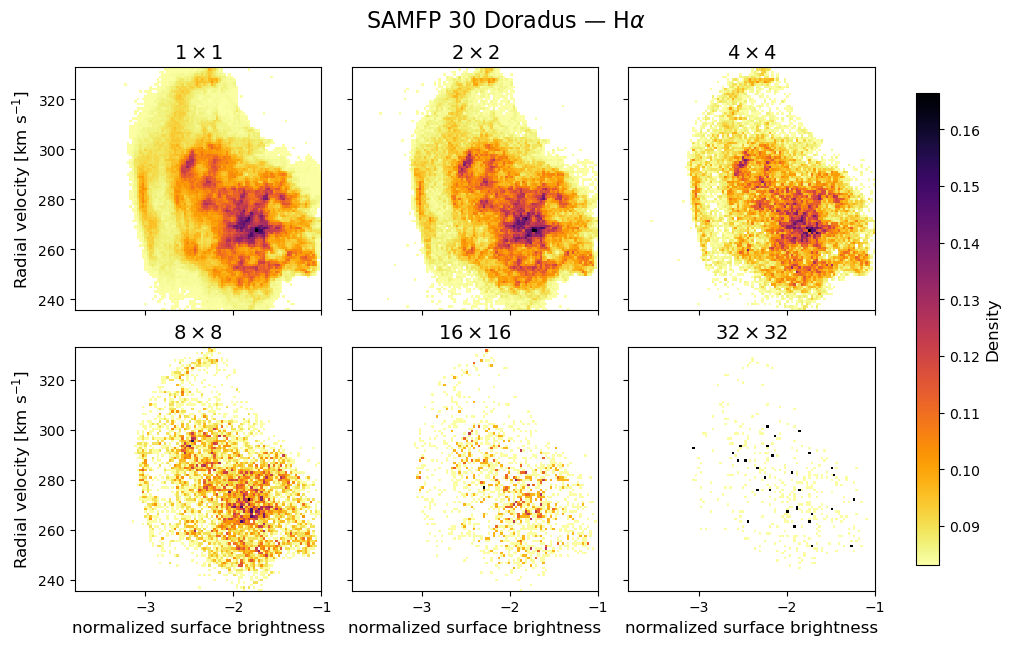

In [20]:
datasets_by_bin = ha_muse

bin_labels = {
    bin_level: rf"${2**bin_level}\times{2**bin_level}$"
    for bin_level in BINS
}

bin_order = list(BINS)

# Surface-brightness range is kept from the original diagnostic.
xrange = [-3.8, -1.0]

# Use one common radial-velocity range for all panels, derived from the
# complete 30 Dor sample. This avoids Orion-specific hard-coded limits.
v_lo, v_hi = np.nanpercentile(processed_data["VV"], [0.5, 99.5])
ypad = 0.05 * (v_hi - v_lo)
yrange = [v_lo - ypad, v_hi + ypad]

nbins_hist = 100

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = axes.flatten()
im = None

for ax, bin_id in zip(axes, bin_order):

    data = datasets_by_bin[bin_id]

    SB = np.asarray(data["SB"])
    VV = np.asarray(data["VV"])

    mask = (
        np.isfinite(SB)
        & np.isfinite(VV)
        & (SB > 0)
    )

    SB_valid = SB[mask]
    VV_valid = VV[mask]

    # Same normalization convention as the original notebook.
    SB_norm = SB_valid / (np.nanmedian(SB_valid) * 100)

    x = np.log10(SB_norm)
    y = VV_valid

    H, xedges, yedges = np.histogram2d(
        x,
        y,
        bins=nbins_hist,
        range=[xrange, yrange],
        density=True,
    )

    HH = np.where(H == 0, np.nan, H)

    im = ax.imshow(
        HH.T,
        origin="lower",
        aspect="auto",
        cmap="inferno_r",
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        interpolation="nearest",
    )

    ax.set_title(bin_labels[bin_id], fontsize=14)
    ax.set_xlim(xrange)
    ax.set_ylim(yrange)
    ax.grid(False)

for idx, ax in enumerate(axes):
    row = idx // 3
    col = idx % 3

    if col == 0:
        ax.set_ylabel(
            r"Radial velocity [km s$^{-1}$]",
            fontsize=12,
        )

    if row == 1:
        ax.set_xlabel(
            r"normalized surface brightness",
            fontsize=12,
        )

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.9,
    pad=0.03,
)

fig.suptitle(
    r"SAMFP 30 Doradus — H$\alpha$",
    fontsize=16,
    y=1.05,
)

cbar.set_label("Density", fontsize=12)

fig.savefig(
    FIGS_DIR / "SAMFP_sb_vs_vv_bins.pdf",
    dpi=600,
    bbox_inches="tight",
)

plt.show()


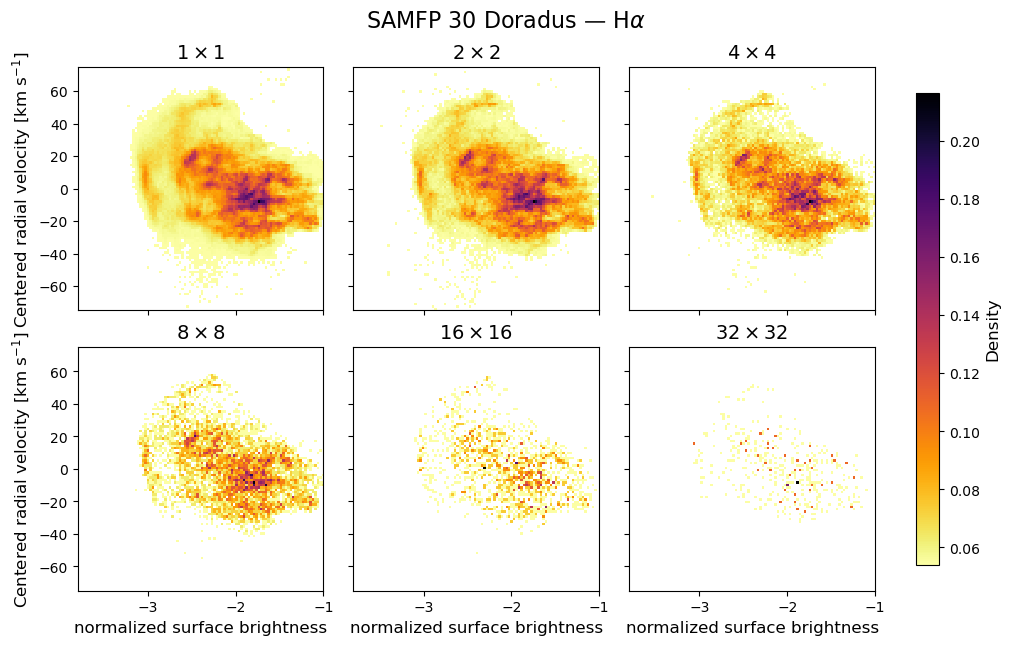

In [19]:
datasets_by_bin = ha_muse

bin_labels = {
    bin_level: rf"${2**bin_level}\times{2**bin_level}$"
    for bin_level in BINS
}

bin_order = list(BINS)

xrange = [-3.8, -1.0]

# Common centered-velocity range for all panels.
rv_lo, rv_hi = np.nanpercentile(processed_data["RV_centered"], [0.5, 99.5])
rv_span = max(abs(rv_lo), abs(rv_hi))
yrange = [-75, 75]

nbins_hist = 100

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = axes.flatten()
im = None

for ax, bin_id in zip(axes, bin_order):

    data = datasets_by_bin[bin_id]

    SB = np.asarray(data["SB"])
    RV = np.asarray(data["RV_centered"])

    mask = (
        np.isfinite(SB)
        & np.isfinite(RV)
        & (SB > 0)
    )

    SB_valid = SB[mask]
    RV_valid = RV[mask]

    SB_norm = SB_valid / (np.nanmedian(SB_valid) * 100)

    x = np.log10(SB_norm)
    y = RV_valid

    H, xedges, yedges = np.histogram2d(
        x,
        y,
        bins=nbins_hist,
        range=[xrange, yrange],
        density=True,
    )

    HH = np.where(H == 0, np.nan, H)

    im = ax.imshow(
        HH.T,
        origin="lower",
        aspect="auto",
        cmap="inferno_r",
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        interpolation="nearest",
    )

    ax.set_title(bin_labels[bin_id], fontsize=14)
    ax.set_xlim(xrange)
    ax.set_ylim(yrange)
    ax.grid(False)

for idx, ax in enumerate(axes):
    row = idx // 3
    col = idx % 3

    if col == 0:
        ax.set_ylabel(
            r"Centered radial velocity [km s$^{-1}$]",
            fontsize=12,
        )

    if row == 1:
        ax.set_xlabel(
            r"normalized surface brightness",
            fontsize=12,
        )

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.9,
    pad=0.03,
)

fig.suptitle(
    r"SAMFP 30 Doradus — H$\alpha$",
    fontsize=16,
    y=1.05,
)

cbar.set_label("Density", fontsize=12)

fig.savefig(
    FIGS_DIR / "SAMFP_sb_vs_centered_vv_bins.pdf",
    dpi=600,
    bbox_inches="tight",
)

plt.show()
